# Feature redundancy
Area and Convex_Area show very similar distributions, as observed from their boxplots and descriptive statistics. The scatter plot also shows an extremely strong linear relationship between the two features, which is supported by their correlation coefficient of approximately 1.00. Both features exhibit similar class patterns. Therefore, Area and Convex_Area contain highly similar information and may be redundant. To reduce potential redundancy in Logistic Regression, we will evaluate a reduced feature set by removing one of these features and compare its performance with the model using both features.

In [1]:
features_set1 = ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']
features_set2 = ['Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']
features_set3 = ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Extent']

## Convert bytes to strings

In [2]:
import pandas as pd

train_set1 = pd.read_csv("train_set1.csv")

X_train_set1 = train_set1.drop(columns=["Target"])
y_train_set1 = train_set1["Target"]

train_set2 = pd.read_csv("train_set2.csv")

X_train_set2 = train_set2.drop(columns=["Target"])
y_train_set2 = train_set2["Target"]

train_set3 = pd.read_csv("train_set3.csv")

X_train_set3 = train_set3.drop(columns=["Target"])
y_train_set3 = train_set3["Target"]

# Train the model without Convex_Area (set3)

In [3]:
features_outliers_set3 = ['Eccentricity', 'Minor_Axis_Length', 'Area']
features_non_outliers_set3  = ['Extent', 'Major_Axis_Length', 'Perimeter']

# Train base model

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
import numpy as np

random_forest_model = RandomForestClassifier(
    random_state=42
)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    random_forest_model,
    X_train_set3,
    y_train_set3,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

## Evaluate model

In [5]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.99958983 1.         1.         1.         1.        ]
Validation accuracy: [0.92622951 0.93114754 0.9295082  0.90311987 0.9228243 ]
Mean training accuracy: 0.9999179655455291
Mean validation accuracy: 0.9225658833346791
Validation accuracy std: 0.010133873673829105
Mean F1: 0.9209064284925189
Mean Precision: 0.9212857891437466
Mean Recall: 0.9208301137433634


## Hyperparameter tuning

In [6]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# Random Forest pipeline
pipeline_rf = Pipeline([
    ('model', RandomForestClassifier(random_state=42))
])

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# Hyperparameter grid
param_grid_rf = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10, 20],
    'model__max_features': ['sqrt', 'log2']
}

# Grid Search
grid_search_rf = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid_rf,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

# Train
grid_search_rf.fit(X_train_set3, y_train_set3)

print("Best Parameters:", grid_search_rf.best_params_)
print("Best CV Accuracy:", grid_search_rf.best_score_)

Best Parameters: {'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__n_estimators': 100}
Best CV Accuracy: 0.9301176343912353


In [7]:
# Obtain best model

best_random_forest = grid_search_rf.best_estimator_

In [8]:
results = pd.DataFrame(grid_search_rf.cv_results_)
best_results = results.loc[grid_search_rf.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_rf.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__n_estimators': 100}
Mean Train Accuracy:      0.9437
Mean CV Accuracy:         0.9301
Mean CV Precision:        0.9289
Mean CV Recall:           0.9287
Mean CV F1-Score:         0.9286
Train-CV Accuracy Gap:    0.0136
No strong overfitting signal based on this accuracy gap.


In [9]:
best_rf_set3 = grid_search_rf.best_estimator_

print("Best parameters:", grid_search_rf.best_params_)
print("Best CV accuracy:", grid_search_rf.best_score_)

Best parameters: {'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__n_estimators': 100}
Best CV accuracy: 0.9301176343912353


# Train the model without Area (set2)

In [10]:
features_outliers_set2 = ['Eccentricity', 'Minor_Axis_Length', 'Convex_Area']
features_non_outliers_set2  = ['Extent', 'Major_Axis_Length', 'Perimeter']

# Train base model

In [11]:
random_forest_model = RandomForestClassifier(
    random_state=42
)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    random_forest_model,
    X_train_set2,
    y_train_set2,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

## Evaluate model

In [12]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.99958983 1.         1.         1.         1.        ]
Validation accuracy: [0.9295082  0.93278689 0.93114754 0.90804598 0.92775041]
Mean training accuracy: 0.9999179655455291
Mean validation accuracy: 0.925847802094269
Validation accuracy std: 0.009057168334128951
Mean F1: 0.9241917619125102
Mean Precision: 0.9250062963249809
Mean Recall: 0.9237953455496187


## Hyperparameter tuning

In [13]:
# Random Forest pipeline
pipeline_rf = Pipeline([
    ('model', RandomForestClassifier(random_state=42))
])

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# Hyperparameter grid
param_grid_rf = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10, 20],
    'model__max_features': ['sqrt', 'log2']
}

# Grid Search
grid_search_rf = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid_rf,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

# Train
grid_search_rf.fit(X_train_set2, y_train_set2)

print("Best Parameters:", grid_search_rf.best_params_)
print("Best CV Accuracy:", grid_search_rf.best_score_)

Best Parameters: {'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__n_estimators': 300}
Best CV Accuracy: 0.9291334894613584


In [14]:
# Obtain best model

best_random_forest = grid_search_rf.best_estimator_

In [15]:
results = pd.DataFrame(grid_search_rf.cv_results_)
best_results = results.loc[grid_search_rf.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_rf.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__n_estimators': 300}
Mean Train Accuracy:      0.9432
Mean CV Accuracy:         0.9291
Mean CV Precision:        0.9283
Mean CV Recall:           0.9273
Mean CV F1-Score:         0.9276
Train-CV Accuracy Gap:    0.0141
No strong overfitting signal based on this accuracy gap.


# Train the model with all features (set1)

In [16]:
features_outliers_set1 = ['Eccentricity', 'Minor_Axis_Length', 'Area', 'Convex_Area']
features_non_outliers_set1  = ['Extent', 'Major_Axis_Length', 'Perimeter']

# Train base model

In [17]:
random_forest_model = RandomForestClassifier(
    random_state=42
)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    random_forest_model,
    X_train_set1,
    y_train_set1,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

## Evaluate model

In [18]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.99958983 1.         1.         1.         1.        ]
Validation accuracy: [0.92459016 0.93114754 0.92459016 0.90804598 0.9228243 ]
Mean training accuracy: 0.9999179655455291
Mean validation accuracy: 0.92223962959972
Validation accuracy std: 0.007644638962158863
Mean F1: 0.9205138229461172
Mean Precision: 0.9212469008300284
Mean Recall: 0.9201602659106858


## Hyperparameter tuning

In [19]:
# Random Forest pipeline
pipeline_rf = Pipeline([
    ('model', RandomForestClassifier(random_state=42))
])

# Hyperparameter grid
param_grid_rf = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10, 20],
    'model__max_features': ['sqrt', 'log2']
}

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# Grid Search
grid_search_rf = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid_rf,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

# Train
grid_search_rf.fit(X_train_set1, y_train_set1)

print("Best Parameters:", grid_search_rf.best_params_)
print("Best CV Accuracy:", grid_search_rf.best_score_)

Best Parameters: {'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__n_estimators': 300}
Best CV Accuracy: 0.9294613583138173


In [20]:
# Obtain best model

best_random_forest = grid_search_rf.best_estimator_

In [21]:
results = pd.DataFrame(grid_search_rf.cv_results_)
best_results = results.loc[grid_search_rf.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_rf.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__n_estimators': 300}
Mean Train Accuracy:      0.9436
Mean CV Accuracy:         0.9295
Mean CV Precision:        0.9285
Mean CV Recall:           0.9277
Mean CV F1-Score:         0.9279
Train-CV Accuracy Gap:    0.0141
No strong overfitting signal based on this accuracy gap.


# Evaluate models removing outliers

## Outlier distribution of training and testing set
(Model without redundant feature 'Area')

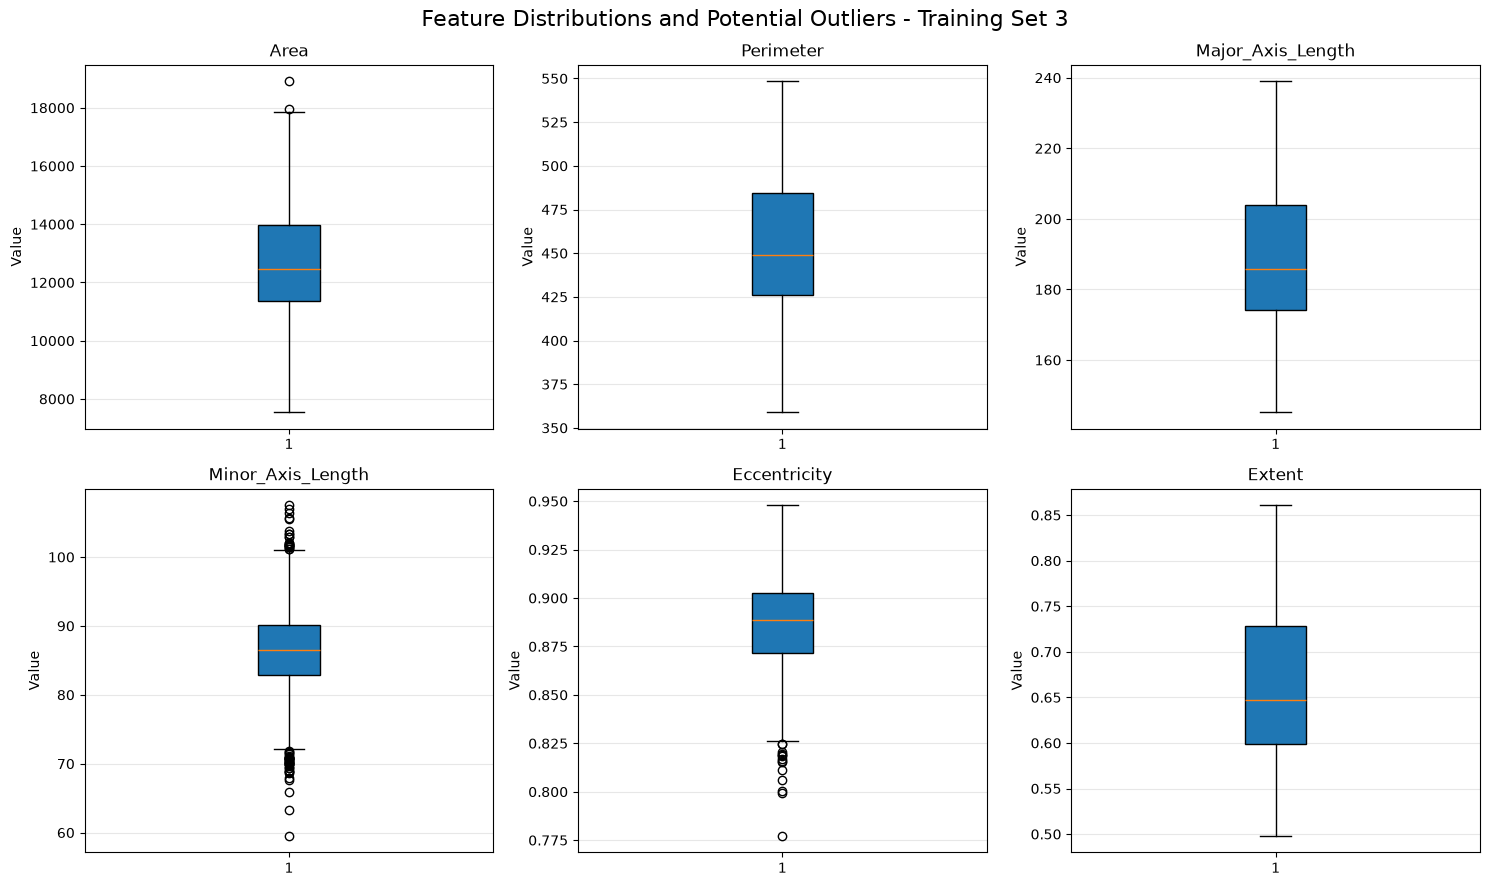

In [22]:
import matplotlib.pyplot as plt

features_set2 = X_train_set3.columns

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(15, 9)
)

axes = axes.flatten()

for i, feature in enumerate(features_set3):
    axes[i].boxplot(
        X_train_set3[feature],
        patch_artist=True
    )
    
    axes[i].set_title(feature)
    axes[i].set_ylabel("Value")
    axes[i].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Feature Distributions and Potential Outliers - Training Set 3",
    fontsize=16
)

plt.tight_layout()
plt.show()

In training set, Minor_Axis_Length, Eccentricity and Area has outliers.

In [24]:
outlier_features = [
    "Minor_Axis_Length",
    "Eccentricity",
    "Area"
]

# Calculate all bounds from the original training data
mask = pd.Series(True, index=X_train_set3.index)

for feature in outlier_features:
    Q1 = X_train_set3[feature].quantile(0.25)
    Q3 = X_train_set3[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    mask &= X_train_set3[feature].between(
        lower_bound, upper_bound
    )

# Apply one combined mask
X_train_set3_clean = X_train_set3.loc[mask].copy()
y_train_set3_clean = y_train_set3.loc[mask].copy()

print("Original training rows:", len(X_train_set3))
print("Clean training rows:", len(X_train_set3_clean))
print("Rows removed:", len(X_train_set3) - len(X_train_set3_clean))


Original training rows: 3048
Clean training rows: 2978
Rows removed: 70


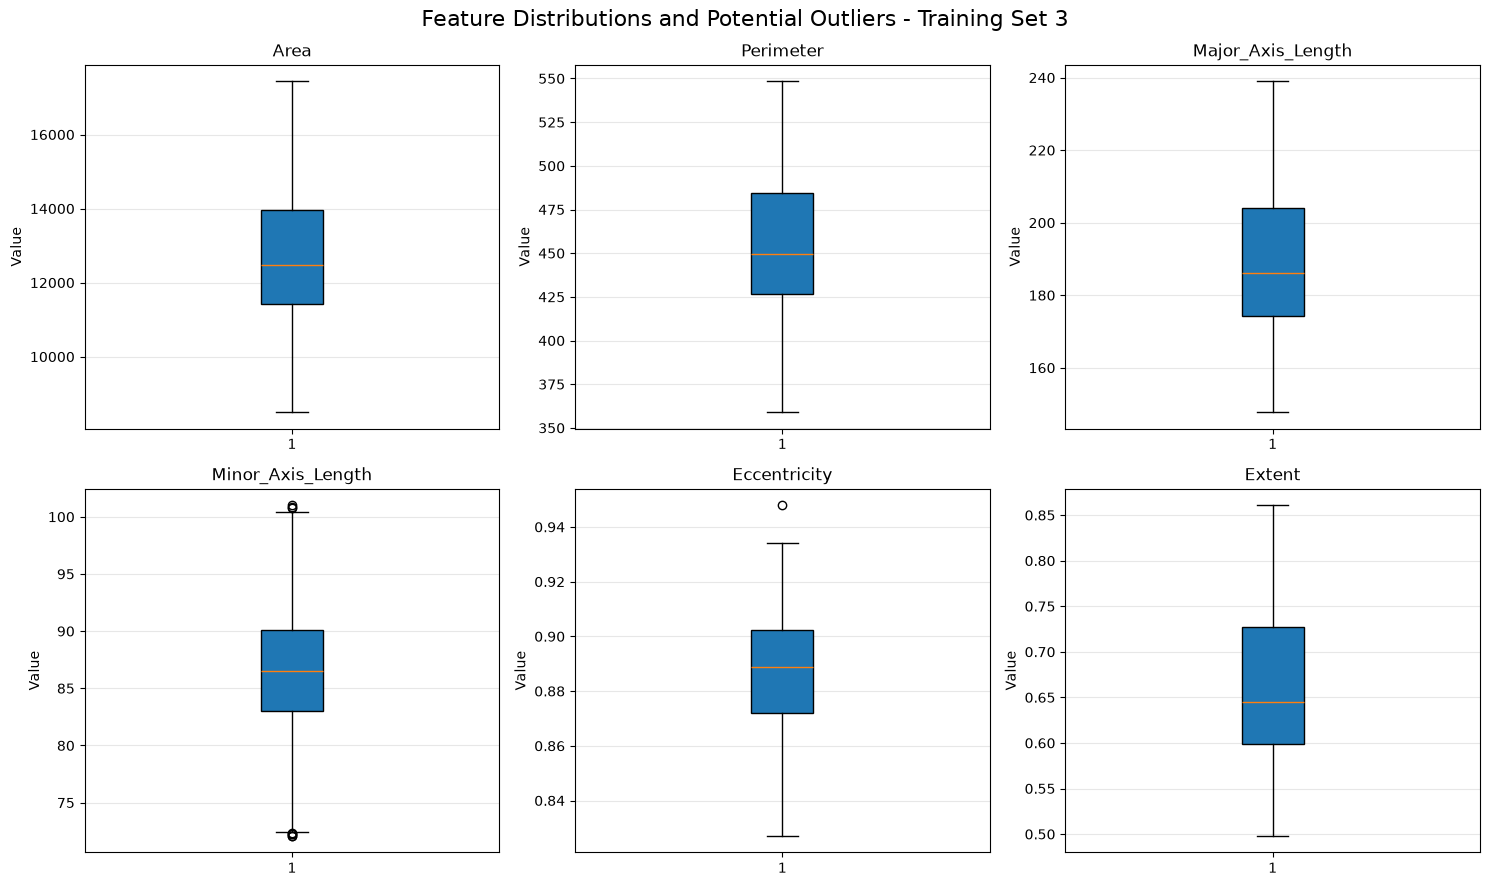

In [25]:
features_set3 = X_train_set3_clean.columns

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(15, 9)
)

axes = axes.flatten()

for i, feature in enumerate(features_set3):
    axes[i].boxplot(
        X_train_set3_clean[feature],
        patch_artist=True
    )
    
    axes[i].set_title(feature)
    axes[i].set_ylabel("Value")
    axes[i].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Feature Distributions and Potential Outliers - Training Set 3",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Train the model without Convex_Area (set3)

In [26]:
features_outliers_set3 = ['Eccentricity', 'Minor_Axis_Length', 'Area']
features_non_outliers_set3  = ['Extent', 'Major_Axis_Length', 'Perimeter']

# Train base model

In [27]:
random_forest_model = RandomForestClassifier(
    random_state=42
)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    random_forest_model,
    X_train_set3_clean,
    y_train_set3_clean,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

## Evaluate model

In [28]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [1. 1. 1. 1. 1.]
Validation accuracy: [0.91946309 0.92785235 0.9295302  0.92268908 0.9210084 ]
Mean training accuracy: 1.0
Mean validation accuracy: 0.924108623315098
Validation accuracy std: 0.003914498052044608
Mean F1: 0.9225691184722736
Mean Precision: 0.9231174050464654
Mean Recall: 0.9225922536790447


## Hyperparameter tuning

In [29]:
# Random Forest pipeline
pipeline_rf = Pipeline([
    ('model', RandomForestClassifier(random_state=42))
])

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# Hyperparameter grid
param_grid_rf = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10, 20],
    'model__max_features': ['sqrt', 'log2']
}

# Grid Search
grid_search_rf = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid_rf,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

# Train
grid_search_rf.fit(X_train_set3_clean, y_train_set3_clean)

print("Best Parameters:", grid_search_rf.best_params_)
print("Best CV Accuracy:", grid_search_rf.best_score_)

Best Parameters: {'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__n_estimators': 200}
Best CV Accuracy: 0.9298167052055722


In [30]:
# Obtain best model

best_random_forest = grid_search_rf.best_estimator_

In [31]:
results = pd.DataFrame(grid_search_rf.cv_results_)
best_results = results.loc[grid_search_rf.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_rf.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__n_estimators': 200}
Mean Train Accuracy:      0.9432
Mean CV Accuracy:         0.9298
Mean CV Precision:        0.9290
Mean CV Recall:           0.9282
Mean CV F1-Score:         0.9284
Train-CV Accuracy Gap:    0.0133
No strong overfitting signal based on this accuracy gap.


# Check class imbalance

In [32]:
class_distribution = pd.DataFrame({
    "Count": y_train_set3.value_counts(),
    "Percentage": y_train_set3.value_counts(normalize=True) * 100
})

print(class_distribution)

          Count  Percentage
Target                     
Osmancik   1744   57.217848
Cammeo     1304   42.782152


### Balance the classes using SMOTE

In [33]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_set3_balanced, y_train_set3_balanced = smote.fit_resample(
    X_train_set3,
    y_train_set3
)

In [34]:
class_distribution_balanced = pd.DataFrame({
    "Count": y_train_set3_balanced.value_counts(),
    "Percentage": y_train_set3_balanced.value_counts(normalize=True) * 100
})

print(class_distribution_balanced)

          Count  Percentage
Target                     
Osmancik   1744        50.0
Cammeo     1744        50.0


### Train the final selected model

# Train base model

In [35]:
rf_model = RandomForestClassifier(random_state=42)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    rf_model,
    X_train_set3_balanced,
    y_train_set3_balanced,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

## Evaluate model

In [36]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.99964158 1.         1.         1.         1.        ]
Validation accuracy: [0.92550143 0.93982808 0.93409742 0.8866571  0.93974175]
Mean training accuracy: 0.9999283154121864
Mean validation accuracy: 0.9251651572642474
Validation accuracy std: 0.019951176040338785
Mean F1: 0.9251609342771833
Mean Precision: 0.925252183106171
Mean Recall: 0.9251646741099364


## Hyperparameter tuning

In [38]:
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Random Forest + SMOTE pipeline
pipeline_rf_smote = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('model', RandomForestClassifier(random_state=42))
])

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# Smaller hyperparameter grid
param_grid_rf = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 5, 10],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2],
    'model__max_features': ['sqrt']
}

# Grid Search with 5-fold CV
grid_search_rf_smote = GridSearchCV(
    estimator=pipeline_rf_smote,
    param_grid=param_grid_rf,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

# Train using the original training data
grid_search_rf_smote.fit(X_train_set3, y_train_set3)

# Results
print("Best Parameters:", grid_search_rf_smote.best_params_)
print("Best CV Accuracy:", grid_search_rf_smote.best_score_)


Best Parameters: {'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV Accuracy: 0.9301187111362351


In [39]:
# Obtain best model

best_rf = grid_search_rf_smote.best_estimator_

# Train test evaluation

In [40]:
results = pd.DataFrame(grid_search_rf_smote.cv_results_)
best_results = results.loc[grid_search_rf_smote.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_rf_smote.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Mean Train Accuracy:      0.9423
Mean CV Accuracy:         0.9301
Mean CV Precision:        0.9282
Mean CV Recall:           0.9300
Mean CV F1-Score:         0.9288
Train-CV Accuracy Gap:    0.0122
No strong overfitting signal based on this accuracy gap.


# Forward feature selection

In [42]:

import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate

cv_ffs = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

selected_features = []
remaining_features = X_train_set3.columns.tolist()
ffs_results = []

while remaining_features:

    candidate_results = []

    for feature in remaining_features:

        candidate_features = selected_features + [feature]

        # Clone the tuned Random Forest model
        model = clone(best_rf_set3)

        # Calculate training and validation metrics
        scores = cross_validate(
            model,
            X_train_set3[candidate_features],
            y_train_set3,
            cv=cv_ffs,
            scoring=scoring_metrics,
            return_train_score=True,
            n_jobs=-1
        )

        candidate_results.append({
            "Feature": feature,
            "Train Accuracy": scores["train_accuracy"].mean(),
            "Mean CV Accuracy": scores["test_accuracy"].mean(),
            "CV Std": scores["test_accuracy"].std(),
            "Precision": scores["test_precision"].mean(),
            "Recall": scores["test_recall"].mean(),
            "F1-Score": scores["test_f1"].mean()
        })

    # Select the feature that gives the highest mean CV accuracy
    candidate_results.sort(
        key=lambda x: x["Mean CV Accuracy"],
        reverse=True
    )

    best_candidate = candidate_results[0]

    selected_features.append(best_candidate["Feature"])
    remaining_features.remove(best_candidate["Feature"])

    ffs_results.append({
        "Step": len(selected_features),
        "Added Feature": best_candidate["Feature"],
        "Selected Features": selected_features.copy(),
        "Number of Features": len(selected_features),
        "Train Accuracy": best_candidate["Train Accuracy"],
        "Mean CV Accuracy": best_candidate["Mean CV Accuracy"],
        "CV Std": best_candidate["CV Std"],
        "Precision": best_candidate["Precision"],
        "Recall": best_candidate["Recall"],
        "F1-Score": best_candidate["F1-Score"]
    })

# Display results for every FFS step
ffs_df = pd.DataFrame(ffs_results)

display(ffs_df.round(4))

# Find the feature subset with the highest mean CV accuracy
best_idx = ffs_df["Mean CV Accuracy"].idxmax()
best_row = ffs_df.loc[best_idx]

best_features_ffs = best_row["Selected Features"]

print("\nBest feature subset:", best_features_ffs)
print("Number of features:", len(best_features_ffs))
print("Train accuracy:", round(best_row["Train Accuracy"], 4))
print("Mean CV accuracy:", round(best_row["Mean CV Accuracy"], 4))
print("CV standard deviation:", round(best_row["CV Std"], 4))
print("Macro precision:", round(best_row["Precision"], 4))
print("Macro recall:", round(best_row["Recall"], 4))
print("Macro F1-score:", round(best_row["F1-Score"], 4))


,Step,Added Feature,Selected Features,Number of Features,Train Accuracy,Mean CV Accuracy,CV Std,Precision,Recall,F1-Score
0,1,Major_Axis_Length,[Major_Axis_Length],1,0.9395,0.9262,0.0105,0.9249,0.9246,0.9246
1,2,Minor_Axis_Length,"[Major_Axis_Length, Minor_Axis_Length]",2,0.9393,0.9314,0.0121,0.9305,0.9298,0.9300
2,3,Extent,"[Major_Axis_Length, Minor_Axis_Length, Extent]",3,0.9380,0.9327,0.0116,0.9315,0.9315,0.9313
3,4,Eccentricity,"[Major_Axis_Length, Minor_Axis_Length, Extent,...",4,0.9402,0.9291,0.0110,0.9279,0.9276,0.9276
4,5,Area,"[Major_Axis_Length, Minor_Axis_Length, Extent,...",5,0.9422,0.9291,0.0118,0.9282,0.9274,0.9276
5,6,Perimeter,"[Major_Axis_Length, Minor_Axis_Length, Extent,...",6,0.9430,0.9278,0.0108,0.9268,0.9261,0.9263



Best feature subset: ['Major_Axis_Length', 'Minor_Axis_Length', 'Extent']
Number of features: 3
Train accuracy: 0.938
Mean CV accuracy: 0.9327
CV standard deviation: 0.0116
Macro precision: 0.9315
Macro recall: 0.9315
Macro F1-score: 0.9313


In [43]:

import joblib
from datetime import datetime
from sklearn.base import clone

# 1. Find the best feature subset from Random Forest FFS
best_idx = ffs_df["Mean CV Accuracy"].idxmax()
best_row = ffs_df.loc[best_idx]

best_features_ffs = list(best_row["Selected Features"])

print("Selected features:", best_features_ffs)

# 2. Create a fresh copy of the tuned Random Forest
final_rf_ffs = clone(best_rf_set3)

# 3. Train the final model using the selected features
final_rf_ffs.fit(
    X_train_set3[best_features_ffs],
    y_train_set3
)

# 4. Store the model and the information needed later
model_bundle = {
    "model": final_rf_ffs,
    "selected_features": best_features_ffs,
    "model_name": "Random Forest - Set 3 FFS",
    "hyperparameters": final_rf_ffs.get_params(),
    "cv_metrics": {
        "train_accuracy": float(best_row["Train Accuracy"]),
        "mean_cv_accuracy": float(best_row["Mean CV Accuracy"]),
        "cv_std": float(best_row["CV Std"]),
        "precision_macro": float(best_row["Precision"]),
        "recall_macro": float(best_row["Recall"]),
        "f1_macro": float(best_row["F1-Score"])
    },
    "saved_at": datetime.now().isoformat()
}

# 5. Save everything in one file
joblib.dump(
    model_bundle,
    "random_forest_set3_ffs.joblib"
)

print("\nModel saved successfully!")
print("File: random_forest_set3_ffs.joblib")
print("Number of selected features:", len(best_features_ffs))
print(f"Mean CV accuracy: {best_row['Mean CV Accuracy']:.2%}")


Selected features: ['Major_Axis_Length', 'Minor_Axis_Length', 'Extent']

Model saved successfully!
File: random_forest_set3_ffs.joblib
Number of selected features: 3
Mean CV accuracy: 93.27%


| Feature set | Train-Accuracy | CV-Accuracy | Precision | Recall | F1-Score |
|---|---:|---:|---:|---:|--:|
| Set 3 | 94.37% | 93.01% | 92.89% | 92.87% | 92.86% | 
| Set 2 | 94.32% | 92.91% | 92.83% | 92.73% | 92.76% |
| Set 1 | 94.36% | 92.95% | 92.85% | 92.77% | 92.79% |
| Set 3 (SMOTE) | 94.23% | 93.01% | 92.82% | 93.00% | 92.88% |
| Set 3 (Remove outlier) | 94.32% | 92.98% | 92.90% | 92.82% |92.84% |
| Set 3 (FFS) | 93.80% | 93.27% | 93.15% | 93.15% | 93.13% |

## Conclusion: Random Forest Model Comparison

Based on the experimental results, **Set 3 with Forward Feature Selection (FFS)** is the preferred candidate among the evaluated Random Forest configurations. It achieved the highest mean cross-validation accuracy of **93.27%**, with a macro precision of **93.15%**, macro recall of **93.15%**, and macro F1-score of **93.13%**.

Compared with the standard Set 3 model, which achieved 93.01% mean CV accuracy, Set 3 (FFS) improved accuracy by **0.26 percentage points**. Its training accuracy was 93.80%, compared with 94.37% for standard Set 3. If FFS uses fewer input features, it can also simplify the model and reduce the number of measurements required for prediction.

The Set 3 (SMOTE) experiment achieved 93.01% mean CV accuracy, equal to the standard Set 3 model, although its macro recall increased to 93.00%. The outlier-removal experiment achieved 92.98% CV accuracy, while Set 1 and Set 2 achieved 92.95% and 92.91%, respectively. Therefore, neither SMOTE nor outlier removal improved overall CV accuracy beyond Set 3 (FFS).

Overall, **Set 3 (FFS) provides the best reported cross-validation performance** among the evaluated configurations. However, the improvement over standard Set 3 is relatively small. Since FFS evaluates multiple feature subsets using cross-validation, its best CV score may be optimistic. Therefore, the selected FFS model and the standard Set 3 model should be evaluated on the same untouched test set before the final model is selected. The final decision should consider test-set performance, the number of selected features, and the model's practical requirements.
